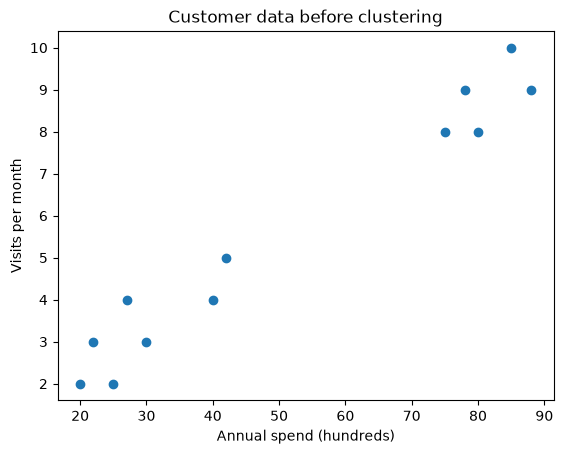

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.DataFrame({
    "AnnualSpend": [20,22,25,27,30,75,78,80,85,88,40,42],
    "VisitsPerMonth": [2,3,2,4,3,8,9,8,10,9,4,5]
})
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"])
plt.xlabel("Annual spend (hundreds)")
plt.ylabel("Visits per month")
plt.title("Customer data before clustering")
plt.show()

C:\Users\kesav\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


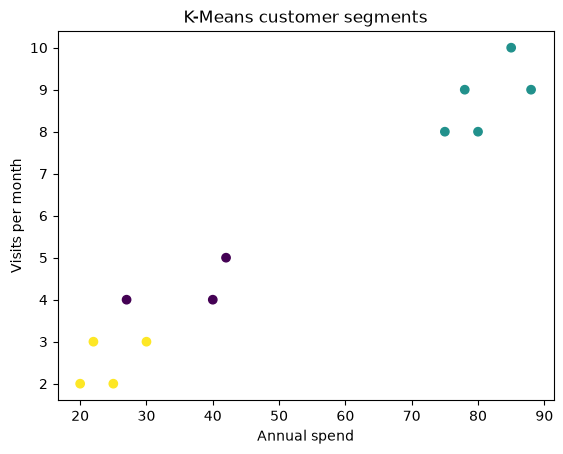

    AnnualSpend  VisitsPerMonth  Cluster
0            20               2        2
1            22               3        2
2            25               2        2
3            27               4        0
4            30               3        2
5            75               8        1
6            78               9        1
7            80               8        1
8            85              10        1
9            88               9        1
10           40               4        0
11           42               5        0


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

km = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster"] = km.fit_predict(X_scaled)

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=customers["Cluster"])
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("K-Means customer segments")
plt.show()
print(customers)

Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


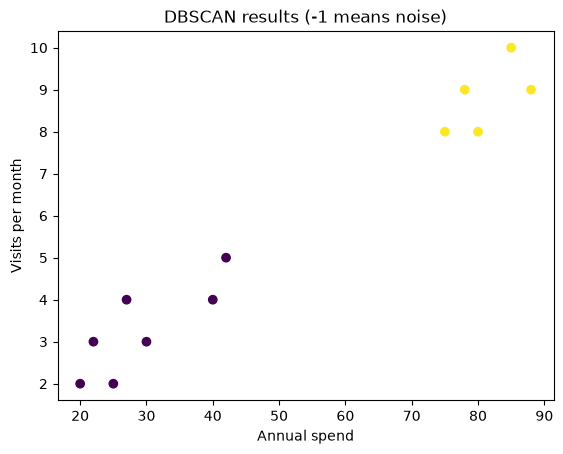

In [4]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=2)
db_labels = db.fit_predict(X_scaled)

print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=db_labels)
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("DBSCAN results (-1 means noise)")
plt.show()

Explained variance: [0.73  0.229]


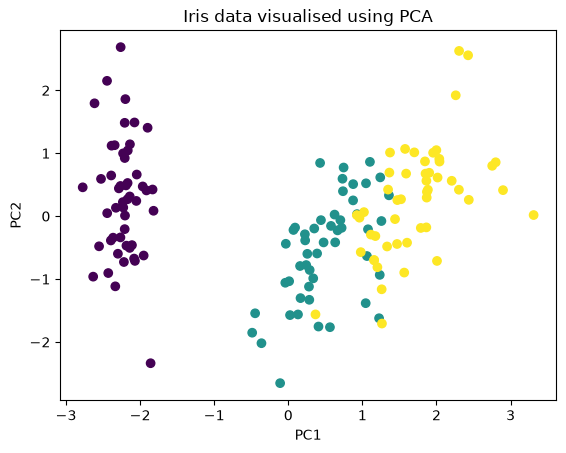

In [5]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_iris)

print("Explained variance:",
      pca.explained_variance_ratio_.round(3))
plt.scatter(X_2d[:,0], X_2d[:,1], c=iris.target)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Iris data visualised using PCA")
plt.show()

In [6]:
from sklearn.ensemble import IsolationForest
import numpy as np

transactions = np.array([
    [20, 2], [22, 3], [18, 2], [25, 3],
    [21, 2], [23, 4], [19, 3], [250, 20]
])

detector = IsolationForest(contamination=0.12, random_state=42)
labels = detector.fit_predict(transactions)

for row, label in zip(transactions, labels):
    print(row, "Anomaly" if label == -1 else "Normal")

[20  2] Normal
[22  3] Normal
[18  2] Normal
[25  3] Normal
[21  2] Normal
[23  4] Normal
[19  3] Normal
[250  20] Anomaly


CUSTOMER DATASET
    Customer_ID  Annual_Spending  Visits_Per_Month
0             1             2000                 2
1             2             2500                 3
2             3             3000                 2
3             4             3500                 4
4             5             4000                 3
5             6             4500                 5
6             7             5000                 4
7             8             5500                 5
8             9             6000                 4
9            10             6500                 6
10           11            15000                10
11           12            16000                11
12           13            17000                 9
13           14            18000                12
14           15            19000                11
15           16            20000                13
16           17            21000                12
17           18            22000                14
18           1

C:\Users\kesav\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


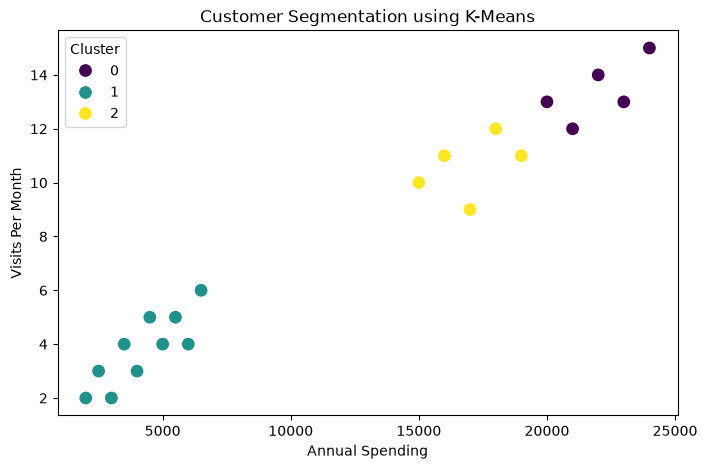


AVERAGE SPENDING PER CLUSTER
Cluster
0    22000.0
1     4250.0
2    17000.0
Name: Annual_Spending, dtype: float64


C:\Users\kesav\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kesav\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kesav\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kesav\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

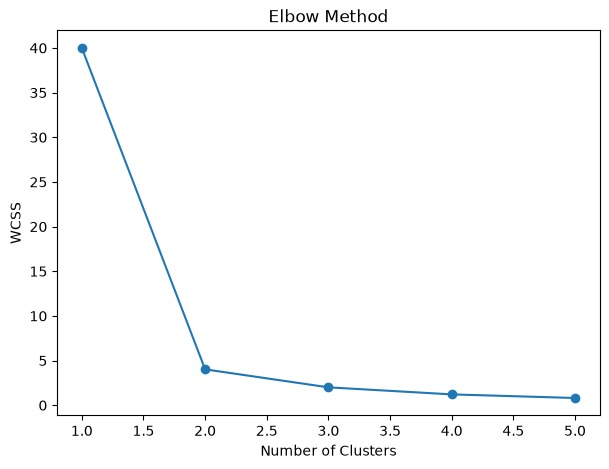


SILHOUETTE SCORE COMPARISON
K = 2 Silhouette Score = 0.779
K = 3 Silhouette Score = 0.644
K = 4 Silhouette Score = 0.497

DBSCAN CLUSTERING
    Customer_ID  Annual_Spending  Visits_Per_Month  Cluster  DBSCAN_Cluster
0             1             2000                 2        1               0
1             2             2500                 3        1               0
2             3             3000                 2        1               0
3             4             3500                 4        1               0
4             5             4000                 3        1               0
5             6             4500                 5        1               0
6             7             5000                 4        1               0
7             8             5500                 5        1               0
8             9             6000                 4        1               0
9            10             6500                 6        1               0
10           11        

C:\Users\kesav\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kesav\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kesav\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


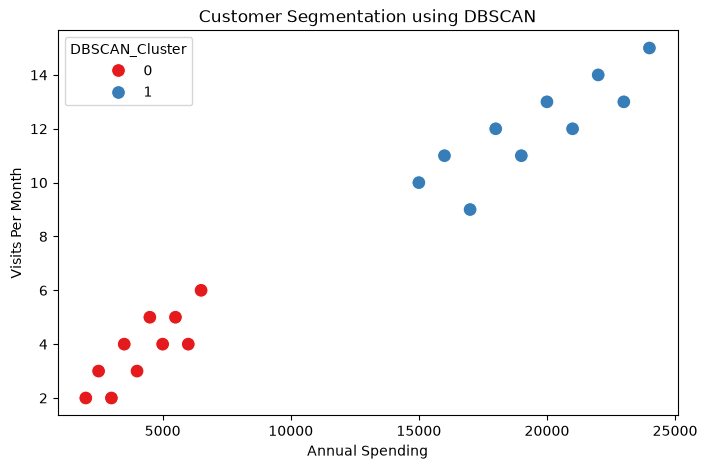


NOISE POINTS (-1)
Empty DataFrame
Columns: [Customer_ID, Annual_Spending, Visits_Per_Month, Cluster, DBSCAN_Cluster]
Index: []

CUSTOMER SEGMENT DESCRIPTIONS

Cluster 0
Average Annual Spending: 22000.0
Average Monthly Visits: 13.4
Customer Type: High-spending customers

Cluster 1
Average Annual Spending: 4250.0
Average Monthly Visits: 3.8
Customer Type: Low-spending customers

Cluster 2
Average Annual Spending: 17000.0
Average Monthly Visits: 10.6
Customer Type: Medium-spending customers

Practical 2 Completed Successfully!


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# 1. Create Customer Dataset

data = {
    'Customer_ID': range(1, 21),
    'Annual_Spending': [
        2000, 2500, 3000, 3500, 4000,
        4500, 5000, 5500, 6000, 6500,
        15000, 16000, 17000, 18000, 19000,
        20000, 21000, 22000, 23000, 24000
    ],
    'Visits_Per_Month': [
        2, 3, 2, 4, 3, 5, 4, 5, 4, 6,
        10, 11, 9, 12, 11, 13, 12, 14, 13, 15
    ]
}

df = pd.DataFrame(data)

print("CUSTOMER DATASET")
print(df)

# 2. Scale Features and Apply K-Means (K=3)

X = df[['Annual_Spending', 'Visits_Per_Month']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("\nK-MEANS CLUSTERING (K=3)")
print(df)

# 3. Visualize Clusters

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Annual_Spending',
    y='Visits_Per_Month',
    hue='Cluster',
    palette='viridis',
    s=100
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Spending")
plt.ylabel("Visits Per Month")
plt.show()

# Calculate Average Spending

print("\nAVERAGE SPENDING PER CLUSTER")
print(df.groupby('Cluster')['Annual_Spending'].mean())

# 4. Elbow Method

wcss = []

for k in range(1, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 6), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

# Silhouette Score Comparison

print("\nSILHOUETTE SCORE COMPARISON")

for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    print("K =", k, "Silhouette Score =", round(score, 3))

# 5. Apply DBSCAN

dbscan = DBSCAN(eps=0.7, min_samples=3)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print("\nDBSCAN CLUSTERING")
print(df)

# Visualize DBSCAN

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Annual_Spending',
    y='Visits_Per_Month',
    hue='DBSCAN_Cluster',
    palette='Set1',
    s=100
)

plt.title("Customer Segmentation using DBSCAN")
plt.xlabel("Annual Spending")
plt.ylabel("Visits Per Month")
plt.show()

# Display Noise Points

print("\nNOISE POINTS (-1)")
print(df[df['DBSCAN_Cluster'] == -1])

# Final Customer Segment Descriptions

print("\nCUSTOMER SEGMENT DESCRIPTIONS")

for cluster in sorted(df['Cluster'].unique()):
    group = df[df['Cluster'] == cluster]

    spending = group['Annual_Spending'].mean()
    visits = group['Visits_Per_Month'].mean()

    print("\nCluster", cluster)
    print("Average Annual Spending:", round(spending, 2))
    print("Average Monthly Visits:", round(visits, 2))

    if spending < 8000:
        print("Customer Type: Low-spending customers")
    elif spending < 18000:
        print("Customer Type: Medium-spending customers")
    else:
        print("Customer Type: High-spending customers")

print("\nPractical 2 Completed Successfully!")

Libraries imported successfully
    AnnualSpend  VisitsPerMonth
0            20               2
1            22               3
2            25               2
3            27               4
4            30               3
5            75               8
6            78               9
7            80               8
8            85              10
9            88               9
10           40               4
11           42               5


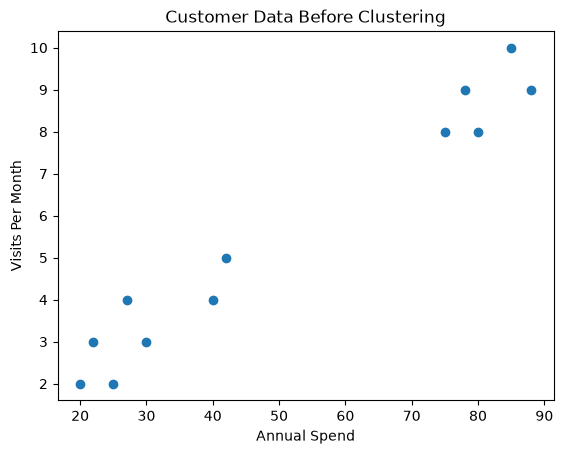

Data scaled successfully
[[-1.17392805 -1.24808193]
 [-1.09819076 -0.89978   ]
 [-0.98458482 -1.24808193]
 [-0.90884753 -0.55147806]
 [-0.79524158 -0.89978   ]
 [ 0.90884753  0.84172968]
 [ 1.02245347  1.19003161]
 [ 1.09819076  0.84172968]
 [ 1.28753399  1.53833354]
 [ 1.40113993  1.19003161]
 [-0.41655512 -0.55147806]
 [-0.34081782 -0.20317613]]
Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


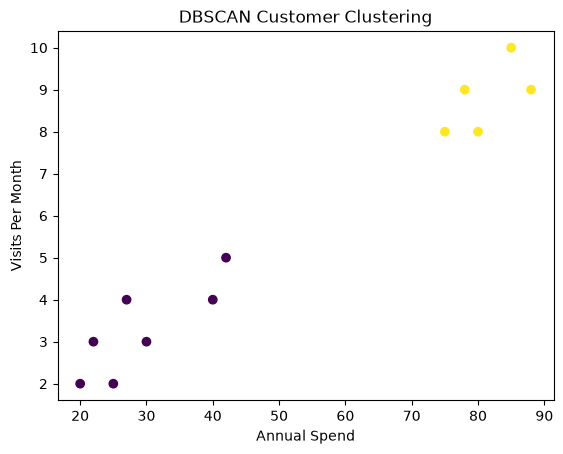

    AnnualSpend  VisitsPerMonth  Cluster
0            20               2        0
1            22               3        0
2            25               2        0
3            27               4        0
4            30               3        0
5            75               8        1
6            78               9        1
7            80               8        1
8            85              10        1
9            88               9        1
10           40               4        0
11           42               5        0
New cluster labels: [ 0 -1  0 -1 -1  1 -1  1 -1 -1 -1 -1]
Noise points: 8


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

print("Libraries imported successfully")
customers = pd.DataFrame({
    "AnnualSpend": [20, 22, 25, 27, 30, 75, 78, 80, 85, 88, 40, 42],
    "VisitsPerMonth": [2, 3, 2, 4, 3, 8, 9, 8, 10, 9, 4, 5]
})

print(customers)
plt.scatter(customers["AnnualSpend"], customers["VisitsPerMonth"])

plt.xlabel("Annual Spend")
plt.ylabel("Visits Per Month")
plt.title("Customer Data Before Clustering")

plt.show()
scaler = StandardScaler()

X_scaled = scaler.fit_transform(customers)

print("Data scaled successfully")
print(X_scaled)
db = DBSCAN(eps=0.8, min_samples=2)

db_labels = db.fit_predict(X_scaled)

print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))
plt.scatter(
    customers["AnnualSpend"],
    customers["VisitsPerMonth"],
    c=db_labels
)

plt.xlabel("Annual Spend")
plt.ylabel("Visits Per Month")
plt.title("DBSCAN Customer Clustering")

plt.show()
customers["Cluster"] = db_labels

print(customers)
db_test = DBSCAN(eps=0.2, min_samples=2)

test_labels = db_test.fit_predict(X_scaled)

print("New cluster labels:", test_labels)
print("Noise points:", sum(test_labels == -1))